# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [2]:
import random
from dataclasses import dataclass
from collections import Counter
import statistics
import matplotlib.pyplot as plt

SUITS = ["Hearts", "Diamonds", "Clubs", "Spades"]
RANKS = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K", "A"]

@dataclass(frozen=True)
class Card:
    rank: str
    suit: str

    @property
    def value(self):
        if self.rank == "A":
            return 11
        if self.rank in {"K", "Q", "J", "10"}:
            return 10
        return int(self.rank)

    @property
    def count_value(self):
        if self.rank in {"2", "3", "4", "5", "6"}:
            return 1
        if self.rank in {"7", "8", "9"}:
            return 0
        return -1

    def __str__(self):
        return f"{self.rank} of {self.suit}"


@dataclass(frozen=True)
class PlasticCard:
    """Cut/plastic card used to trigger a shuffle before the next deal."""
    def __str__(self):
        return "PLASTIC CARD"


class Deck:
    def __init__(self, num_decks=6, seed=None):
        if num_decks < 1:
            raise ValueError("num_decks must be at least 1")
        self.num_decks = num_decks
        self.rng = random.Random(seed)
        self.cards = []
        self.needs_shuffle = False
        self.build()
        self.shuffle()

    def build(self):
        self.cards = [Card(rank, suit)
                      for _ in range(self.num_decks)
                      for suit in SUITS
                      for rank in RANKS]
        # Put the plastic card near the last portion of the shoe at a random position.
        low = max(1, int(len(self.cards) * 0.65))
        high = max(low, int(len(self.cards) * 0.85))
        plastic_index = self.rng.randint(low, high)
        self.cards.insert(plastic_index, PlasticCard())
        self.needs_shuffle = False

    def shuffle(self):
        # Rebuilds the shoe, so previously used cards are not retained.
        self.build()
        self.rng.shuffle(self.cards)
        # Move the plastic card back into the late part of the shoe after shuffling.
        plastic = next(card for card in self.cards if isinstance(card, PlasticCard))
        self.cards.remove(plastic)
        low = max(1, int(len(self.cards) * 0.65))
        high = max(low, int(len(self.cards) * 0.85))
        self.cards.insert(self.rng.randint(low, high), plastic)
        self.needs_shuffle = False

    def draw(self):
        if not self.cards:
            self.shuffle()
        card = self.cards.pop()
        if isinstance(card, PlasticCard):
            self.needs_shuffle = True
        return card

    def cards_remaining(self):
        return len(self.cards)


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

In [ ]:
# UML-style relationship map for the implemented classes
#
#                  +----------------+
#                  |      Card      |
#                  +----------------+
#                  | rank, suit     |
#                  | value          |
#                  | count_value    |
#                  +----------------+
#                          ^
#                          |
#                  +----------------+
#                  |  PlasticCard   |
#                  +----------------+
#                          ^
#                          |
#                  +----------------+
#                  |      Deck      |
#                  +----------------+
#                  | cards          |
#                  | draw()         |
#                  | shuffle()      |
#                  +----------------+
#                          |
#                          v
#                  +----------------+
#                  |      Hand      |
#                  +----------------+
#                  | cards          |
#                  | total()        |
#                  | blackjack()    |
#                  | busted()       |
#                  +----------------+
#                          ^
#                          |
#                  +----------------+
#                  |     Player     |
#                  +----------------+
#                  | name, chips    |
#                  | hand           |
#                  | strategy()     |
#                  +----------------+
#                     ^    ^    ^    ^
#                     |    |    |    |
#                  Dealer Human Basic Count
#
#                  +----------------------+
#                  |    BlackjackGame     |
#                  +----------------------+
#                  | deck, dealer, players|
#                  | play_round()         |
#                  | play_game()          |
#                  | settle_hand()        |
#                  +----------------------+


3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [3]:
class Hand:
    def __init__(self):
        self.cards = []

    def add(self, card):
        self.cards.append(card)

    def clear(self):
        self.cards.clear()

    def total(self):
        total = sum(card.value for card in self.cards)
        aces = sum(card.rank == "A" for card in self.cards)
        while total > 21 and aces:
            total -= 10
            aces -= 1
        return total

    def blackjack(self):
        return len(self.cards) == 2 and self.total() == 21

    def busted(self):
        return self.total() > 21

    def __str__(self):
        return ", ".join(str(c) for c in self.cards)


class Player:
    def __init__(self, name, chips=100, bet=10):
        self.name = name
        self.chips = chips
        self.default_bet = bet
        self.hand = Hand()
        self.current_bet = 0
        self.count = 0

    def reset_hand(self):
        self.hand.clear()
        self.current_bet = 0

    def place_bet(self):
        self.current_bet = min(self.default_bet, self.chips)
        self.chips -= self.current_bet
        return self.current_bet

    def observe(self, card):
        if isinstance(card, Card):
            self.count += card.count_value

    def reset_count(self):
        self.count = 0

    def wants_hit(self, game):
        raise NotImplementedError


class Dealer(Player):
    def wants_hit(self, game):
        # Casino rule: hit through 16, stand on 17 or higher.
        return self.hand.total() < 17


class HumanPlayer(Player):
    def wants_hit(self, game):
        while True:
            choice = input(f"{self.name}: {self.hand.total()} — Hit or stand? [h/s]: ").strip().lower()
            if choice in {"h", "hit"}:
                return True
            if choice in {"s", "stand"}:
                return False
            print("Please enter h or s.")


class BasicStrategyPlayer(Player):
    """Simple dealer-like automated strategy used for comparison players."""
    def wants_hit(self, game):
        return self.hand.total() < 17


class CountStrategyPlayer(Player):
    """Card-count strategy required by Requirement 6.

    Cards 2-6 = +1, 7-9 = 0, 10-A = -1.
    The player hits when the running count is at/below the threshold,
    but must still hit whenever the hand is below 17 to avoid standing
    on an obviously weak hand. Once at 17+, the threshold controls the
    hit/stay choice.
    """
    def __init__(self, name, chips=100, bet=10, threshold=0):
        super().__init__(name, chips, bet)
        self.threshold = threshold

    def wants_hit(self, game):
        total = self.hand.total()
        if total >= 21:
            return False
        if total < 17:
            return True
        return self.count <= self.threshold


class BlackjackGame:
    def __init__(self, players, dealer=None, num_decks=6, verbose=True, seed=None):
        self.players = players
        self.dealer = dealer if dealer is not None else Dealer("Dealer")
        self.deck = Deck(num_decks=num_decks, seed=seed)
        self.verbose = verbose
        self.rng = random.Random(seed)
        self.round_number = 0

    @property
    def active_players(self):
        return [p for p in self.players if p.chips > 0]

    def _announce(self, message):
        if self.verbose:
            print(message)

    def _draw_to(self, player, reveal=True):
        card = self.deck.draw()
        # Plastic card signals the end of this shoe. It is not a playable card.
        if isinstance(card, PlasticCard):
            self._announce("[Plastic card reached — shoe will be reshuffled after this draw sequence.]")
            if not self.deck.cards:
                self.deck.shuffle()
            card = self.deck.draw()
            self.deck.needs_shuffle = True
        player.hand.add(card)
        if reveal:
            for p in self.players:
                p.observe(card)
            self.dealer.observe(card)
        return card

    def _initial_deal(self):
        for p in self.players:
            p.hand.clear()
        self.dealer.hand.clear()
        for _ in range(2):
            for p in self.players:
                if p.current_bet > 0:
                    self._draw_to(p, reveal=True)
            # Dealer's first card is exposed; hole card is hidden until later.
            self._draw_to(self.dealer, reveal=( _ == 0))

    def _reveal_dealer_hole_card(self):
        # Any dealer card not already counted is now visible.
        for card in self.dealer.hand.cards:
            if card.rank != "__seen__":
                # We track exposure separately so all actual cards can be revealed exactly once.
                pass
        # Simpler and robust: rebuild each player's count from all cards that are now visible.
        # This is only called after the hole card is revealed.
        for p in self.players + [self.dealer]:
            p.observe(self.dealer.hand.cards[1])

    def _player_turn(self, player):
        while not player.hand.busted() and player.hand.total() < 21:
            if not player.wants_hit(self):
                break
            self._draw_to(player, reveal=True)

    def _dealer_turn(self):
        # Hole card becomes visible before dealer acts.
        if len(self.dealer.hand.cards) >= 2:
            hole = self.dealer.hand.cards[1]
            for p in self.players + [self.dealer]:
                p.observe(hole)
        while not self.dealer.hand.busted() and self.dealer.hand.total() < 17:
            self._draw_to(self.dealer, reveal=True)

    def _payout(self):
        dealer_total = self.dealer.hand.total()
        dealer_bj = self.dealer.hand.blackjack()
        results = {}
        for p in self.players:
            if p.current_bet <= 0:
                results[p.name] = 0
                continue
            bet = p.current_bet
            if p.hand.busted():
                net = -bet
            elif p.hand.blackjack() and not dealer_bj:
                # Standard blackjack payout: 3:2.
                p.chips += int(bet * 2.5)
                net = int(bet * 1.5)
            elif dealer_bj and not p.hand.blackjack():
                net = -bet
            elif self.dealer.hand.busted() or p.hand.total() > dealer_total:
                p.chips += 2 * bet
                net = bet
            elif p.hand.total() == dealer_total:
                p.chips += bet
                net = 0
            else:
                net = -bet
            results[p.name] = net
        return results

    def play_round(self):
        self.round_number += 1
        active = [p for p in self.players if p.chips > 0]
        if not active:
            return {}
        self.players = active
        for p in self.players:
            p.place_bet()
        self._initial_deal()
        self._announce(f"\n--- Round {self.round_number} ---")
        if self.verbose:
            for p in self.players:
                print(f"{p.name}: {p.hand} (total {p.hand.total()}, count {p.count})")
            print(f"Dealer shows: {self.dealer.hand.cards[0]}" if self.dealer.hand.cards else "Dealer has no cards")
        for p in self.players:
            if not p.hand.blackjack():
                self._player_turn(p)
        self._dealer_turn()
        results = self._payout()
        if self.verbose:
            print(f"Dealer: {self.dealer.hand} (total {self.dealer.hand.total()})")
            for p in self.players:
                print(f"{p.name}: {p.hand.total()} -> net {results[p.name]:+d}, chips ${p.chips}")
        # If the plastic card was reached, reshuffle before the next deal.
        if self.deck.needs_shuffle:
            self.deck.shuffle()
            # A new shoe means the running count starts over.
            for p in self.players + [self.dealer]:
                p.reset_count()
        return results

    def play_game(self, rounds=50):
        history = []
        for _ in range(rounds):
            if not self.active_players:
                break
            results = self.play_round()
            history.append(results)
        return history


4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [4]:
def play_human_game():
    human = HumanPlayer("You", chips=100, bet=10)
    dealer = Dealer("Dealer")
    game = BlackjackGame([human], dealer=dealer, num_decks=6, verbose=True)
    print("Welcome to Blackjack! You start with $100.")
    while human.chips > 0:
        before = human.chips
        game.play_round()
        if human.chips <= 0:
            print("You are out of chips. Game over!")
            break
        again = input(f"You have ${human.chips}. Play another round? [y/n]: ").strip().lower()
        if again not in {"y", "yes"}:
            break
    print(f"Final chips: ${human.chips} (net ${human.chips - 100:+d})")

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [5]:
players = [BasicStrategyPlayer("Player 1"),
           BasicStrategyPlayer("Player 2"),
           BasicStrategyPlayer("Player 3")]
game_demo = BlackjackGame(players, dealer=Dealer("Dealer"), num_decks=6, verbose=True, seed=42)
game_demo.play_game(rounds=5)



--- Round 1 ---
Player 1: Q of Clubs, 2 of Hearts (total 12, count -2)
Player 2: 10 of Diamonds, 7 of Diamonds (total 17, count -2)
Player 3: Q of Hearts, 7 of Spades (total 17, count -2)
Dealer shows: 8 of Diamonds
Dealer: 8 of Diamonds, 4 of Spades, 5 of Diamonds (total 17)
Player 1: 21 -> net +10, chips $110
Player 2: 17 -> net +0, chips $100
Player 3: 17 -> net +0, chips $100

--- Round 2 ---
Player 1: 4 of Diamonds, Q of Spades (total 14, count 2)
Player 2: 10 of Spades, 2 of Diamonds (total 12, count 2)
Player 3: 9 of Hearts, 2 of Clubs (total 11, count 2)
Dealer shows: 4 of Diamonds
Dealer: 4 of Diamonds, Q of Spades, 9 of Diamonds (total 23)
Player 1: 23 -> net -10, chips $100
Player 2: 19 -> net +10, chips $110
Player 3: 21 -> net +10, chips $110

--- Round 3 ---
Player 1: A of Clubs, 7 of Diamonds (total 18, count 4)
Player 2: 5 of Hearts, 5 of Clubs (total 10, count 4)
Player 3: 5 of Clubs, 3 of Clubs (total 8, count 4)
Dealer shows: 6 of Spades
Dealer: 6 of Spades, 8 of He

[{'Player 1': 10, 'Player 2': 0, 'Player 3': 0},
 {'Player 1': -10, 'Player 2': 10, 'Player 3': 10},
 {'Player 1': 10, 'Player 2': -10, 'Player 3': -10},
 {'Player 1': -10, 'Player 2': -10, 'Player 3': -10},
 {'Player 1': 10, 'Player 2': 15, 'Player 3': -10}]

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [6]:
count_player = CountStrategyPlayer("Counter", chips=100, bet=10, threshold=0)
print("Threshold:", count_player.threshold)
print("2 ->", Card("2", "Hearts").count_value)
print("8 ->", Card("8", "Hearts").count_value)
print("K ->", Card("K", "Hearts").count_value)


Threshold: 0
2 -> 1
8 -> 0
K -> -1


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [7]:
def make_strategy_game(threshold=0, chips=100, bet=10, verbose=False, seed=None):
    strategy = CountStrategyPlayer("Counter", chips=chips, bet=bet, threshold=threshold)
    others = [BasicStrategyPlayer(f"Player {i}", chips=chips, bet=bet) for i in range(1, 4)]
    dealer = Dealer("Dealer")
    game = BlackjackGame([strategy] + others, dealer=dealer, num_decks=6, verbose=verbose, seed=seed)
    return game, strategy

strategy_game, strategy_player = make_strategy_game(threshold=0, verbose=False, seed=7)
history = strategy_game.play_game(rounds=50)
net_winnings = strategy_player.chips - 100
print(f"Strategy player final chips: ${strategy_player.chips}")
print(f"Net winnings after {len(history)} rounds: ${net_winnings:+d}")


Strategy player final chips: $0
Net winnings after 50 rounds: $-100


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Average net winnings per game: $-98.45
Average net winnings per round: $-1.97
Standard deviation: $11.80
Probability of net winning: 1.0%
Probability of net losing: 99.0%
Probability of breaking even: 0.0%


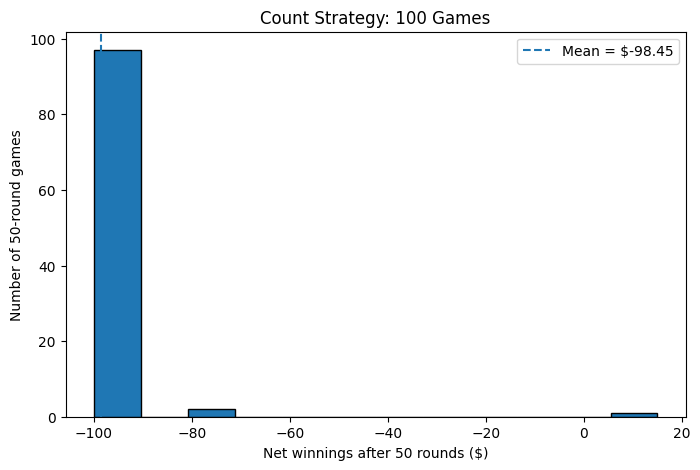

In [8]:
def run_experiment(threshold=0, games=100, rounds=50, seed=12345):
    rng = random.Random(seed)
    winnings = []
    ending_chips = []
    rounds_played = []
    for _ in range(games):
        game_seed = rng.randint(0, 10**9)
        game, strategy = make_strategy_game(threshold=threshold, verbose=False, seed=game_seed)
        game.play_game(rounds=rounds)
        ending_chips.append(strategy.chips)
        winnings.append(strategy.chips - 100)
        rounds_played.append(game.round_number)
    return winnings, ending_chips, rounds_played

winnings, ending_chips, rounds_played = run_experiment(threshold=0)
mean_winnings = statistics.mean(winnings)
std_winnings = statistics.stdev(winnings)
prob_win = sum(w > 0 for w in winnings) / len(winnings)
prob_loss = sum(w < 0 for w in winnings) / len(winnings)
prob_tie = sum(w == 0 for w in winnings) / len(winnings)
avg_per_round = mean_winnings / 50

print(f"Average net winnings per game: ${mean_winnings:.2f}")
print(f"Average net winnings per round: ${avg_per_round:.2f}")
print(f"Standard deviation: ${std_winnings:.2f}")
print(f"Probability of net winning: {prob_win:.1%}")
print(f"Probability of net losing: {prob_loss:.1%}")
print(f"Probability of breaking even: {prob_tie:.1%}")

plt.figure(figsize=(8, 5))
plt.hist(winnings, bins=12, edgecolor="black")
plt.axvline(mean_winnings, linestyle="--", label=f"Mean = ${mean_winnings:.2f}")
plt.xlabel("Net winnings after 50 rounds ($)")
plt.ylabel("Number of 50-round games")
plt.title("Count Strategy: 100 Games")
plt.legend()
plt.show()


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

In [ ]:
thresholds = [-4, -2, 0, 2, 4]
threshold_results = {}

for threshold in thresholds:
    vals, _, _ = run_experiment(threshold=threshold, games=100, rounds=50, seed=2026 + threshold + 10)
    threshold_results[threshold] = {
        "average_net": statistics.mean(vals),
        "std_dev": statistics.stdev(vals),
        "win_probability": sum(v > 0 for v in vals) / len(vals),
        "loss_probability": sum(v < 0 for v in vals) / len(vals),
        "avg_per_round": statistics.mean(vals) / 50,
    }

print("Threshold | Avg net | Avg/round | Std dev | P(win) | P(loss)")
for t, r in threshold_results.items():
    print(f"{t:9d} | ${r['average_net']:7.2f} | ${r['avg_per_round']:9.2f} | ${r['std_dev']:7.2f} | {r['win_probability']:6.1%} | {r['loss_probability']:7.1%}")

best_threshold = max(threshold_results, key=lambda t: threshold_results[t]["average_net"])
print(f"\nBest tested threshold by average net winnings: {best_threshold}")


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [ ]:
class CountAdjustedPlayer(Player):
    """Alternative strategy: basic play with a running-count adjustment.

    - Below 17: hit.
    - 17+: stand.
    - On 16: stand when count >= 2, otherwise hit.
    - On 15: stand when count >= 3, otherwise hit.
    This is intentionally a simple educational strategy, not a complete
    casino basic-strategy table.
    """
    def wants_hit(self, game):
        total = self.hand.total()
        if total <= 14:
            return True
        if total == 15:
            return self.count < 3
        if total == 16:
            return self.count < 2
        return total < 17


def make_alternative_game(chips=100, bet=10, verbose=False, seed=None):
    strategy = CountAdjustedPlayer("Adjusted Counter", chips=chips, bet=bet)
    others = [BasicStrategyPlayer(f"Player {i}", chips=chips, bet=bet) for i in range(1, 4)]
    game = BlackjackGame([strategy] + others, dealer=Dealer("Dealer"), num_decks=6,
                         verbose=verbose, seed=seed)
    return game, strategy


def compare_strategies(games=100, rounds=50, seed=777):
    rng = random.Random(seed)
    required_vals, alternative_vals = [], []
    for _ in range(games):
        s = rng.randint(0, 10**9)
        g1, p1 = make_strategy_game(threshold=0, verbose=False, seed=s)
        g1.play_game(rounds=rounds)
        required_vals.append(p1.chips - 100)

        s2 = rng.randint(0, 10**9)
        g2, p2 = make_alternative_game(verbose=False, seed=s2)
        g2.play_game(rounds=rounds)
        alternative_vals.append(p2.chips - 100)
    return required_vals, alternative_vals

required_vals, alternative_vals = compare_strategies()
print(f"Required count strategy average net: ${statistics.mean(required_vals):.2f}")
print(f"Adjusted count strategy average net: ${statistics.mean(alternative_vals):.2f}")
print(f"Required count strategy P(win): {sum(x > 0 for x in required_vals)/len(required_vals):.1%}")
print(f"Adjusted count strategy P(win): {sum(x > 0 for x in alternative_vals)/len(alternative_vals):.1%}")

plt.figure(figsize=(8, 5))
plt.hist(required_vals, bins=12, alpha=0.55, label="Required threshold strategy")
plt.hist(alternative_vals, bins=12, alpha=0.55, label="Adjusted count strategy")
plt.xlabel("Net winnings after 50 rounds ($)")
plt.ylabel("Number of games")
plt.title("Strategy Comparison")
plt.legend()
plt.show()
